# Analyse ventes en ligne : Nettoyage des données

Remarque
---
Ce notebook est volontairement détaillé. Au-delà du nettoyage des données, il présente les contrôles réalisés et le raisonnement ayant conduit aux différentes décisions de traitement. Cette approche vise à rendre la démarche de nettoyage pleinement transparente.

---
# 1. Mise en place
---

## 1.1 Import

In [1]:
# Import des modules
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sqlalchemy import create_engine, text

# Import des données
# La colonne "Row ID" est le numéro de la ligne dans la base de données, elle peut être exclue. La colonne "Ship Date" est convertie en datetime.
df = pd.read_csv("Sample - Superstore.csv", encoding="latin1", usecols = lambda x: x != "Row ID", parse_dates = ["Order Date", "Ship Date"])

# Création copie 
df_clean = df.copy()

## 1.2 Paramètres

In [2]:
# Paramètres de connexion à MySQL à adapter avant exécution
db_user = "root"
db_password = "votre_mot_de_passe"
db_host = "localhost"
db_port = 3306
db_name = "store_db"

# Voulez-vous exporter les tables de faits et de dimension au format csv ? 
export_csv = "oui"

## 1.3 Fonctions

In [3]:
'''
Objectif :  Connexion à MySQL (database = None) ou à une base de données en particulier (database = nom de la base)
'''

def get_engine(database = None) :
    if database : 
        engine = create_engine(
     f"mysql+pymysql://{db_user}:{db_password}@{db_host}:{db_port}/{database}"
    )
    else : 
        engine = create_engine(
     f"mysql+pymysql://{db_user}:{db_password}@{db_host}:{db_port}"
    )
        
    return engine

In [4]:
'''
Objectif : Création de la base de données
'''

def create_database(engine) :
    with engine.begin() as conn:
        conn.execute(text(f"CREATE DATABASE IF NOT EXISTS {db_name};"))
    print("Base créée.")

In [5]:
'''
Objectif : Création des tables de fait et de dimension dans la base de données créée via la fonction create_database()
'''

def create_tables(engine) : 
    with open("create_tables.sql",
          encoding="utf-8") as file:
        sql_script = file.read()

    with engine.begin() as conn:
        for query in sql_script.split(";"):
            if query.strip():
                conn.execute(text(query))

In [6]:
'''
Objectif : Importer les données dans les tables créées via la fonction create_tables()
'''

def import_data(list_df, engine) :
    for df in list_df : 
        eval(df).to_sql(
        df,
        con=engine,
        if_exists="append",
        index=False
    )

In [7]:
'''
Objectif : Vérifier que l'import s'est passé correctement
'''

def verify_import(engine) : 
    with engine.begin() as conn:
        nb = conn.execute(
            text("SELECT COUNT(*) FROM df_facts")
        ).scalar()

    print(f"{nb} lignes importées.")

---
# 2. Présentation des données
---

In [8]:
df_clean.iloc[:, 0:10].head()

,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State
0,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky
1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky
2,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California
3,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida
4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida


In [9]:
df_clean.iloc[:, 10:20].head()

,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [10]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Order ID       9994 non-null   object        
 1   Order Date     9994 non-null   datetime64[ns]
 2   Ship Date      9994 non-null   datetime64[ns]
 3   Ship Mode      9994 non-null   object        
 4   Customer ID    9994 non-null   object        
 5   Customer Name  9994 non-null   object        
 6   Segment        9994 non-null   object        
 7   Country        9994 non-null   object        
 8   City           9994 non-null   object        
 9   State          9994 non-null   object        
 10  Postal Code    9994 non-null   int64         
 11  Region         9994 non-null   object        
 12  Product ID     9994 non-null   object        
 13  Category       9994 non-null   object        
 14  Sub-Category   9994 non-null   object        
 15  Product Name   9994 n

In [11]:
print(min(df_clean["Order Date"]),max(df_clean["Ship Date"]))

2014-01-03 00:00:00 2018-01-05 00:00:00


Observations : 
---
- Il y a 9994 lignes et 20 colonnes
- Les données s'étendent du 3 janvier 2014 (première commande) au 5 janvier 2018 (dernière expédition)
- **Nom à modifier** :
  - "Sales" en "Total Sales" pour plus de clarté
  - En minuscule et en remplaçant les espaces par des underscore pour rendre les variables plus maniables sur SQL
- **Types à modifier** :
  - Order ID, Customer ID, Customer Name, Postal Code, Product ID, Product Name vers string
  - Ship Mode, Segment, Country, City, State, Region, Category, Sub-Category vers category
- **Valeurs manquantes** :
    - Aucune
- **Création de colonnes** :
   - "Price"
   - "Unit Cost"
   - "Unit Profit Margin before discount"
   - "Unit Profit Margin after discount"
- **Division en tables** :
  - Table de fait :
    - Order ID, Order Date, Ship Date, Ship Mode, Customer ID, Location ID, Product ID, Total Sales, Quantity, Discount, Profit, Unit Profit Margin before discount, Unit Profit Margin after discount
  - Tables de dimension :
      - Customer : Order ID, Customer ID, Customer Name, Segment
      - Product : Product ID, Category, Sub-Category, Product Name, Price, Unit Cost
      - Location : Location ID, City, State, Postal Code, Region

---
# 3. Mise en conformité
---

## 3.1 Standardisation des valeurs

In [12]:
# Majuscule pour prénom et nom
df_clean["Customer Name"] = df_clean["Customer Name"].str.title().str.strip()

# Lettre uniquement en majuscule
var_maj = ["Order ID", "Customer ID", "Product ID"]
for var in var_maj : 
    df_clean[var] = df_clean[var].str.upper().str.strip()

## 3.2 Conversion types

In [13]:
# Colonnes vers string
var_string = ["Order ID", "Customer ID", "Customer Name", "Postal Code", "Product ID", "Product Name"]
for var in var_string : 
    df_clean[var] = df_clean[var].astype("string")

# Colonnes vers category 
var_cat = ["Ship Mode", "Segment", "Country", "City", "State", "Region", "Category", "Sub-Category"]
for var in var_cat : 
    df_clean[var] = df_clean[var].astype("category")

## 3.3 Changement de noms 

In [14]:
df_clean.columns = (
    df_clean
    .rename(columns = {"Sales" : "Total Sales"})
    .rename(str.lower, axis = "columns")
    .columns
    .str.replace(" ", "_")
    .str.replace("-", "_")
)

---
# 4. Recherche de doublons
---

In [15]:
dp_all = df_clean.duplicated().sum()
print(f"Nombre de doublons avec toutes les colonnes : {dp_all}")

dp_1 = df_clean.duplicated(["order_id"]).sum()
print(f"Nombre de doublons avec order_id : {dp_1}")

dp_2 = df_clean.duplicated(["order_id", "customer_id"]).sum()
print(f"Nombre de doublons avec order_id + customer_id : {dp_2}")

dp_3 = df_clean.duplicated(["order_id", "customer_id", "product_id"]).sum()
print(f"Nombre de doublons avec order_id + customer_id + product_id : {dp_3}")

Nombre de doublons avec toutes les colonnes : 1
Nombre de doublons avec order_id : 4985
Nombre de doublons avec order_id + customer_id : 4985
Nombre de doublons avec order_id + customer_id + product_id : 8


Observations : 
---
- Il y a 1 ligne parfaitement identique à une autre. Elle est à supprimer sans hésitation.
- Il y a 4 985 lignes qui ont le même identifiant de commande qu'une autre. Il est possible qu'un même identifiant soit utilisé sur plusieurs lignes car plusieurs produits ont été achetés lors d'une même transaction.
- On retrouve le même nombre en contrôlant avec l'identifiant client ce qui est cohérent avec l'interprétation précédente.
- Une fois ajoutée la variable "product_id", le nombre de doublons chute à 8. Ceci vient confirmer l'hypothèse d'une observation composée de l'association d'un identifiant commande ou client et d'un identifiant produit.

In [16]:
df_clean[df_clean.duplicated(["order_id", "customer_id", "product_id"], keep = False)]

,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,state,postal_code,region,product_id,category,sub_category,product_name,total_sales,quantity,discount,profit
350,CA-2016-129714,2016-09-01,2016-09-03,First Class,AB-10060,Adam Bellavance,Home Office,United States,New York City,New York,10009,East,OFF-PA-10001970,Office Supplies,Paper,Xerox 1881,24.560,2,0.0,11.5432
352,CA-2016-129714,2016-09-01,2016-09-03,First Class,AB-10060,Adam Bellavance,Home Office,United States,New York City,New York,10009,East,OFF-PA-10001970,Office Supplies,Paper,Xerox 1881,49.120,4,0.0,23.0864
430,US-2016-123750,2016-04-15,2016-04-21,Standard Class,RB-19795,Ross Baird,Home Office,United States,Gastonia,North Carolina,28052,South,TEC-AC-10004659,Technology,Accessories,Imation Secure+ Hardware Encrypted USB 2.0 Fla...,408.744,7,0.2,76.6395
431,US-2016-123750,2016-04-15,2016-04-21,Standard Class,RB-19795,Ross Baird,Home Office,United States,Gastonia,North Carolina,28052,South,TEC-AC-10004659,Technology,Accessories,Imation Secure+ Hardware Encrypted USB 2.0 Fla...,291.960,5,0.2,54.7425
1300,CA-2016-137043,2016-12-23,2016-12-25,Second Class,LC-17140,Logan Currie,Consumer,United States,Springfield,Virginia,22153,South,FUR-FU-10003664,Furniture,Furnishings,"Electrix Architect's Clamp-On Swing Arm Lamp, ...",572.760,6,0.0,166.1004
1301,CA-2016-137043,2016-12-23,2016-12-25,Second Class,LC-17140,Logan Currie,Consumer,United States,Springfield,Virginia,22153,South,FUR-FU-10003664,Furniture,Furnishings,"Electrix Architect's Clamp-On Swing Arm Lamp, ...",286.380,3,0.0,83.0502
3183,CA-2017-152912,2017-11-09,2017-11-12,Second Class,BM-11650,Brian Moss,Corporate,United States,Columbia,Maryland,21044,East,OFF-ST-10003208,Office Supplies,Storage,Adjustable Depth Letter/Legal Cart,1633.140,9,0.0,473.6106
3184,CA-2017-152912,2017-11-09,2017-11-12,Second Class,BM-11650,Brian Moss,Corporate,United States,Columbia,Maryland,21044,East,OFF-ST-10003208,Office Supplies,Storage,Adjustable Depth Letter/Legal Cart,544.380,3,0.0,157.8702
3405,US-2014-150119,2014-04-23,2014-04-27,Standard Class,LB-16795,Laurel Beltran,Home Office,United States,Columbus,Ohio,43229,East,FUR-CH-10002965,Furniture,Chairs,Global Leather Highback Executive Chair with P...,281.372,2,0.3,-12.0588
3406,US-2014-150119,2014-04-23,2014-04-27,Standard Class,LB-16795,Laurel Beltran,Home Office,United States,Columbus,Ohio,43229,East,FUR-CH-10002965,Furniture,Chairs,Global Leather Highback Executive Chair with P...,281.372,2,0.3,-12.0588


- En observant attentivement les lignes détectées comme doublons selon le critère précédent, on s'aperçoit qu'elles sont identiques en tout point sauf les colonnes "total_sales", "quantity" et "profit".
- Il n'est pas possible à ce stade de savoir s'il s'agit d'erreurs de saisie ou d'enregistrement dans le logiciel.
- Ces lignes seront donc conservées faute d'informations supplémentaires.

In [17]:
df_clean = df_clean.drop_duplicates()

---
# 5. Incohérences
---

## 5.1 Incohérences numériques

In [18]:
pi_sup_sales = len(df_clean[df_clean["total_sales"] < df_clean["profit"]])
print(f"Lignes avec un profit supérieur au total des ventes : {pi_sup_sales}")

sales_neg_nul = len(df_clean[df_clean["total_sales"] <= 0])
print(f"Lignes avec un total des ventes négatif ou nul : {sales_neg_nul}")

qua_neg_nul = len(df_clean[df_clean["quantity"] <= 0])
print(f"Lignes avec une quantité négative ou nulle : {qua_neg_nul}")

dis_neg_un = len(df_clean.query("discount < 0 or discount >=1"))
print(f"Lignes avec une remise négative ou supérieure ou égale à 100% : {dis_neg_un}")

Lignes avec un profit supérieur au total des ventes : 0
Lignes avec un total des ventes négatif ou nul : 0
Lignes avec une quantité négative ou nulle : 0
Lignes avec une remise négative ou supérieure ou égale à 100% : 0


## 5.2 Incohérences identifiants

Certaines variables sont codifiées concernant le nombre de caractères qui les composent. On va donc rechercher des éléments dont la longueur ne correspond pas à ces conventions.

In [19]:
col_len = {
    "order_id" : [14],
    "customer_id" : [8],
    "postal_code" : [4, 5],
    "product_id" : [15]
}

for col, nb in zip(col_len.keys(), col_len.values()) :
    test = df_clean[col].apply(lambda x : pd.notna(x) and len(x) not in nb)
    val = df_clean[test][col].nunique()
    print(f" Valeurs incohérentes {col} : {val}")

 Valeurs incohérentes order_id : 0
 Valeurs incohérentes customer_id : 0
 Valeurs incohérentes postal_code : 0
 Valeurs incohérentes product_id : 0


## 5.3 Incohérences catégories

On observe les valeurs prises par les différentes catégories pour y détecter d'éventuelles anomalies.

In [20]:
col_cat = ["ship_mode", "segment", "country", "state", "region", "category", "sub_category"]

for col in col_cat :
    print(f"Valeurs uniques {col} : {np.unique(df_clean[col])}")

Valeurs uniques ship_mode : ['First Class' 'Same Day' 'Second Class' 'Standard Class']
Valeurs uniques segment : ['Consumer' 'Corporate' 'Home Office']
Valeurs uniques country : ['United States']
Valeurs uniques state : ['Alabama' 'Arizona' 'Arkansas' 'California' 'Colorado' 'Connecticut'
 'Delaware' 'District of Columbia' 'Florida' 'Georgia' 'Idaho' 'Illinois'
 'Indiana' 'Iowa' 'Kansas' 'Kentucky' 'Louisiana' 'Maine' 'Maryland'
 'Massachusetts' 'Michigan' 'Minnesota' 'Mississippi' 'Missouri' 'Montana'
 'Nebraska' 'Nevada' 'New Hampshire' 'New Jersey' 'New Mexico' 'New York'
 'North Carolina' 'North Dakota' 'Ohio' 'Oklahoma' 'Oregon' 'Pennsylvania'
 'Rhode Island' 'South Carolina' 'South Dakota' 'Tennessee' 'Texas' 'Utah'
 'Vermont' 'Virginia' 'Washington' 'West Virginia' 'Wisconsin' 'Wyoming']
Valeurs uniques region : ['Central' 'East' 'South' 'West']
Valeurs uniques category : ['Furniture' 'Office Supplies' 'Technology']
Valeurs uniques sub_category : ['Accessories' 'Appliances' 'Art

Observations : 
---
- La variable "country" ne comporte qu'une seule valeur, "United States". On peut supprimer cette colonne pour alléger le fichier.
- Tous les États de la colonne "state" sont bien aux États-Unis.
- Aucune anomalie concernant les autres variables

In [21]:
df_clean.drop(columns = "country", inplace = True)

## 5.4 Incohérences dans les combinaisons

L'objectif ici est d'identifier d'éventuelles combinaisons de variables qui pourraient être anormales.

In [22]:
# Etats associés à plusieurs régions
state_region = (
        df_clean
        .groupby("state", observed = True)["region"]
        .nunique()
        .gt(1)
        .sum()
    )
print(f"États associés à plusieurs régions : {state_region}")

# Villes associées à plusieurs Etats
city_state = (
        df_clean
        .groupby("city", observed = True)["state"]
        .nunique()
        .gt(1)
        .sum()
    )
print(f"Villes associées à plusieurs Etats : {city_state}")

# Codes Postaux associés à plusieurs villes
pc_city = (
        df_clean
        .groupby("postal_code", observed = True)["city"]
        .nunique()
        .gt(1)
        .sum()
    )
print(f"Codes Postaux associés à plusieurs villes : {pc_city}")

# Villes associées à plusieurs codes postaux
city_pc = (
        df_clean
        .groupby("city", observed = True)["postal_code"]
        .nunique()
        .gt(1)
        .sum()
    )
print(f"Villes associées à plusieurs codes postaux : {city_pc}")

États associés à plusieurs régions : 0
Villes associées à plusieurs Etats : 57
Codes Postaux associés à plusieurs villes : 1
Villes associées à plusieurs codes postaux : 68


Observations : 
--- 
- On retrouve des noms de villes similaires dans plusieurs États, un code postal présent dans plusieurs villes, et des villes ayant plusieurs codes postaux.
- Après vérifications, aucune de ces combinaisons ne relève d'une anomalie apparente.

In [23]:
# Sous-catégorie dans plusieurs catégorie de produits
cat_sub = (
        df_clean
        .groupby("sub_category", observed = True)["category"]
        .nunique()
        .gt(1)
        .sum()
    )
print(f"Sous-catégorie dans plusieurs catégorie de produits : {cat_sub}")

Sous-catégorie dans plusieurs catégorie de produits : 0


## 5.5 Incohérences profils clients

On détermine le nombre de profils avec plusieurs valeurs pour une même variable

In [24]:
col_customer = ["customer_name", "segment", "city", "state", "postal_code", "region"]

print(f"Nombre de profil client unique : {df_clean["customer_id"].nunique()}")
for col in col_customer :
    inf = (
        df_clean
        .groupby("customer_id")[col]
        .nunique()
        .gt(1)
        .sum()
    )
    print(f"Informations en double avec {col} : {inf}")

Nombre de profil client unique : 793
Informations en double avec customer_name : 0
Informations en double avec segment : 0
Informations en double avec city : 780
Informations en double avec state : 778
Informations en double avec postal_code : 780
Informations en double avec region : 766


Observations : 
---
- Il y a 793 identifiants client différents.
- Aucun profil n'est associé à plusieurs noms ou segments.
- 780 profils ont renseigné plusieurs villes de livraison au cours de la période, soit la quasi-intégralité des profils. Ce chiffre est cohérent avec ceux obtenus pour les variables "state", "postal_code" et "region". 
- Etudions la répartition du nombre de villes associées à un même identifiant client.

In [25]:
df_clean.groupby("customer_id")["city"].nunique().describe()

count    793.000000
mean       5.887768
std        2.304752
min        1.000000
25%        4.000000
50%        6.000000
75%        7.000000
max       15.000000
Name: city, dtype: float64

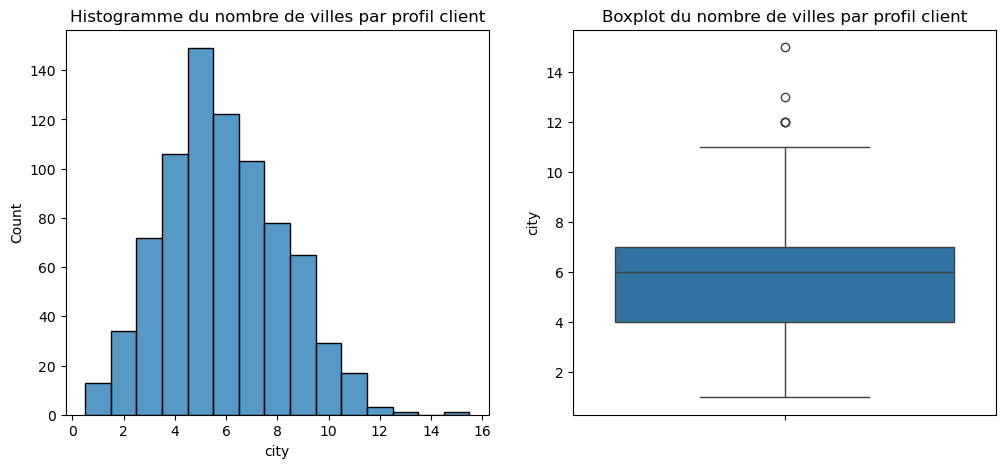

In [26]:
nb_city = df_clean.groupby("customer_id")["city"].nunique()

plt.figure(figsize = (12,5))
plt.subplot(1,2,1)

# On fait un histogramme
sns.histplot(nb_city, discrete=True)
plt.title("Histogramme du nombre de villes par profil client")

plt.subplot(1,2,2)

# On fait une boîte à moustache
sns.boxplot(nb_city)
plt.title("Boxplot du nombre de villes par profil client")

plt.show()

Observations : 
--- 
- Moyenne (5,88) , médiane (6) et mode (5) sont très proches.
- On a une distribution normale du nombre de villes par identifiant client avec une assymétrie sur la droite, c'est-à-dire plus de valeurs hautes présentes.
- Les valeurs 12, 13 et 15 sont détectées comme outliers selon la méthode IQR. 

In [27]:
# Les identifiants des profils clients avec 12 villes ou plus renseignées
id_city = (
    df_clean
    .groupby("customer_id")["city"]
    .nunique()
    .loc[lambda x: x >= 12]
    .index
)

print(f"Nombre de profils concernés : {len(id_city)}")

df_top_city = pd.DataFrame({"customer_id" : id_city})

for i, j in zip(["order_id", "city"], ["Commandes", "Villes"]) :

    df_top_city[f"Nombre {j}"] = (
        df_clean.loc[df_clean["customer_id"].isin(id_city)]
            .value_counts(["customer_id", i])
            .groupby("customer_id")
            .count()
    ).values

df_top_city["segment"] = (
    df_clean.loc[df_clean["customer_id"].isin(id_city)]
        .groupby("customer_id")["segment"]
        .first()
        .values
)

df_top_city

Nombre de profils concernés : 5


,customer_id,Nombre Commandes,Nombre Villes,segment
0,AH-10690,12,12,Corporate
1,EA-14035,13,12,Corporate
2,EP-13915,17,15,Consumer
3,JE-15745,13,13,Consumer
4,NS-18640,13,12,Corporate


In [28]:
df_clean[df_clean["customer_id"] == "EP-13915"][["customer_id", "customer_name", "segment", "city", "state", "postal_code", "region"]]

,customer_id,customer_name,segment,city,state,postal_code,region
536,EP-13915,Emily Phan,Consumer,Chicago,Illinois,60653,Central
1549,EP-13915,Emily Phan,Consumer,New York City,New York,10011,East
2725,EP-13915,Emily Phan,Consumer,Philadelphia,Pennsylvania,19120,East
2726,EP-13915,Emily Phan,Consumer,Philadelphia,Pennsylvania,19120,East
2885,EP-13915,Emily Phan,Consumer,Tempe,Arizona,85281,West
2886,EP-13915,Emily Phan,Consumer,Los Angeles,California,90008,West
2887,EP-13915,Emily Phan,Consumer,Los Angeles,California,90008,West
2888,EP-13915,Emily Phan,Consumer,Los Angeles,California,90008,West
3174,EP-13915,Emily Phan,Consumer,Detroit,Michigan,48227,Central
3473,EP-13915,Emily Phan,Consumer,Dearborn Heights,Michigan,48127,Central


In [29]:
# Combien de commandes passées par ces clients ? 
(
    df_clean
        .value_counts(["customer_id", "order_id"])
        .groupby("customer_id")
        .count()
        .describe()
)

count    793.000000
mean       6.316520
std        2.550885
min        1.000000
25%        5.000000
50%        6.000000
75%        8.000000
max       17.000000
Name: count, dtype: float64

Interprétations : 
--- 
- Parmi ces profils, on retrouve des commandes pour le compte d'entreprises. Ceci est cohérent avec plusieurs villes liées au compte, dans le cas par exemple d'une centralisation des commandes à passer pour différentes antennes d'un même groupe.
- On retrouve également des particuliers. Enregistrer 13 ou 15 villes différentes sur une période de 4 ans peut sembler être anormal mais sans informations complémentaires il est difficile de juger cela incohérent pour autant.
- Ces profils sont donc conservés.

## 5.6 Incohérences Informations Produit

On s'assure que les informations associées à un identifiant produit sont consistantes. Pour se faire, on crée des variables de contrôle, le prix et le coût unitaire, qui vont permettre d'une part de détecter d'éventuelles anomalies plus facilement, et d'autre part d'enrichir l'analyse.

In [30]:
df_clean["price"] = (df_clean["total_sales"]/(1-df_clean["discount"]))/df_clean["quantity"]

# Reconstruction 
df_clean["total_sales"] = df_clean["price"]*df_clean["quantity"]*(1-df_clean["discount"])

# Colonne Cout unitaire
df_clean["unit_cost"] = (df_clean["total_sales"]-df_clean["profit"])/df_clean["quantity"]

# Arrondis au centime
col_arr = ["price", "total_sales", "profit", "unit_cost"]

for col in col_arr : 
    df_clean[col] = round(df_clean[col], 2)

In [31]:
col_product = ["product_name", "category", "sub_category", "price", "unit_cost"]

for col in col_product :
    inf = (
        df_clean
        .groupby("product_id", observed = True)[col]
        .nunique()
        .gt(1)
        .sum()
    )
    print(f"Product ID avec plusieurs {col} : {inf}")

Product ID avec plusieurs product_name : 32
Product ID avec plusieurs category : 0
Product ID avec plusieurs sub_category : 0
Product ID avec plusieurs price : 32
Product ID avec plusieurs unit_cost : 53


Observations : 
---
- Il y a 32 identifiants produit associés à plusieurs noms de produits.
- Il y a également 32 identifiants produit associés à plusieurs prix.
- On retrouve 53 identifiants produits avec plusieurs coûts unitaires
- Mais aucun identifiant n'est associé à plusieurs catégories ou sous-catégories de produit.

On procède en deux étapes : 
- déterminer si la multiplicité des prix et coûts unitaires est due à un problème d'arrondi, auquel cas on aura recours à la médiane comme unique valeur.
- si ce n'est pas le cas, voir si on peut relier ceci au fait que certains identifiants soient associés à plusieurs noms de produits.

In [32]:
for col in ["price", "unit_cost"]:

    stats = (
        df_clean
        .dropna(subset=[col])
        .groupby("product_id")[col]
        .agg(
            nb_values="nunique",
            min_value="min",
            max_value="max"
        )
    )

    stats["difference"] = round(stats["max_value"] - stats["min_value"],2)

    for i in [0, 0.01, 0.02, 0.03, 0.1, 0.2] : 
        anomalous_products = stats.query(
            f"nb_values > 1 and difference > {i}"
        )

        print(f"{col} : {len(anomalous_products)} produits concernés avec un écart supérieur à {i}")

price : 32 produits concernés avec un écart supérieur à 0
price : 32 produits concernés avec un écart supérieur à 0.01
price : 32 produits concernés avec un écart supérieur à 0.02
price : 32 produits concernés avec un écart supérieur à 0.03
price : 32 produits concernés avec un écart supérieur à 0.1
price : 32 produits concernés avec un écart supérieur à 0.2
unit_cost : 53 produits concernés avec un écart supérieur à 0
unit_cost : 32 produits concernés avec un écart supérieur à 0.01
unit_cost : 32 produits concernés avec un écart supérieur à 0.02
unit_cost : 32 produits concernés avec un écart supérieur à 0.03
unit_cost : 32 produits concernés avec un écart supérieur à 0.1
unit_cost : 32 produits concernés avec un écart supérieur à 0.2


Interprétations : 
--- 
- Concernant la variable prix, les écarts sont tous supérieurs à 20 centimes ce qui indique qu'ils ne sont pas dus à un problème d'arrondi des valeurs.
- En revanche, pour le coût unitaire, 21 lignes présentent un écart inférieur ou égal à 1 centime. On peut raisonnablement supposer qu'il s'agit d'une erreur d'arrondi et les remplacer par leur valeur médiane. 

In [33]:
stats = (
    df_clean
    .dropna(subset=["unit_cost"])
    .groupby("product_id")["unit_cost"]
    .agg(
        nb_values="nunique",
        min_value="min",
        max_value="max"
    )
)

anomalous_products = stats.loc[
    (stats["nb_values"] > 1)
    & ((stats["max_value"] - stats["min_value"]).round(2) <= 0.01)
]

median_cost = (
    df_clean
    .groupby("product_id")["unit_cost"]
    .median()
    .round(2)
)

df_clean["unit_cost"] = (
    df_clean["product_id"]
    .map(median_cost.loc[anomalous_products.index])
    .fillna(df_clean["unit_cost"])
)

Après avoir remplacé les coûts unitaires très proches, on identifie la cause des multiples noms, prix et coûts unitaires.

In [34]:
# Liste identifiant produit avec plusieurs prix
list_price = (
    df_clean
    .groupby("product_id")["price"]
    .unique()
    .loc[lambda x: x.apply(len) > 1]
    .index
)

# Liste identifiant produit avec plusieurs coûts unitaires
list_unit_cost = (
    df_clean
    .groupby("product_id")["unit_cost"]
    .unique()
    .loc[lambda x: x.apply(len) > 1]
    .index
)

# Liste identifiant produit avec plusieurs noms
list_product_name = (
    df_clean
    .groupby("product_id")["product_name"]
    .unique()
    .loc[lambda x: x.apply(len) > 1]
    .index
)

# Vérification
print(f"Même liste noms et prix : {set(list_price) == set(list_product_name)}")
print(f"Même liste noms et coûts unitaires : {set(list_unit_cost) == set(list_product_name)}")

Même liste noms et prix : True
Même liste noms et coûts unitaires : True


In [35]:
# Le nombre de noms de produits différents est-il toujours le même que le nombre de prix différents ?
nb_name_nb_price = all(
    len(df_clean[df_clean["product_id"] == i]["product_name"].unique())
    ==
    len(df_clean[df_clean["product_id"] == i]["price"].unique())
    for i in list_product_name
)

# Idem entre le nombre de noms et le nombre de coût
nb_name_nb_unit_cost = all(
    len(df_clean[df_clean["product_id"] == i]["product_name"].unique())
    ==
    len(df_clean[df_clean["product_id"] == i]["unit_cost"].unique())
    for i in list_product_name
)

print(f"Même nombre noms et prix : {nb_name_nb_price}")
print(f"Même nombre noms et coûts unitaires : {nb_name_nb_unit_cost}")

Même nombre noms et prix : True
Même nombre noms et coûts unitaires : True


In [36]:
# Ce nombre est-il toujours égal à 2 ?
all(
    len(df_clean[df_clean["product_id"] == i]["product_name"].unique())
    ==
    2
    for i in list_price
)

True

In [37]:
df_clean[df_clean["product_id"] == list_product_name[23]]["product_name"].unique()

<StringArray>
['Logitech G19 Programmable Gaming Keyboard', 'Plantronics Savi W720 Multi-Device Wireless Headset System']
Length: 2, dtype: string

Interprétations :
---
- Les identifiants ayant plusieurs noms de produit sont les mêmes que ceux ayant plusieurs prix et plusieurs coûts unitaires.
- A chaque fois, le nombre de noms identiques correspond au nombre de prix et de coûts unitaires similaires.
- En prenant par exemple l'identifiant ci-dessus, on voit qu'un clavier d'ordinateur et un casque audio sont enregistrés sous le même identifiant.
- On peut supposer un problème d'identification de certains produits.
- On ajoute une lettre à l'identifiant pour un produit sur 2 afin de les différencier.

In [38]:
for i in list_price :
    change = df_clean[df_clean["product_id"] == i]["product_name"].unique()[0]
    df_clean.loc[df_clean["product_name"] == change, "product_id"] += "A"

## 5.7 Incohérences temporelles

On s'assure que les dates de commande et d'envoi sont cohérentes.

In [39]:
envoi_avant_commande = len(df_clean[df_clean["order_date"] > df_clean["ship_date"]])
print(f"Lignes avec une date d'envoi antérieure à la date de commande : {envoi_avant_commande}")

Lignes avec une date d'envoi antérieure à la date de commande : 0


---
# 6. Outliers
---

La méthode de l'écart interquartile, dite IQR, est mobilisée ici pour détecter d'éventuelles valeurs aberrantes dans les prix des produits selon la sous-catégorie à laquelle ils appartiennent. L'étude se limite aux prix car la variabilité dans les profits est importante à cause des différentes remises. Le coût unitaire sera utilisé en tant que variable de contrôle. 

Une visualisation sous forme de boîtes à moustache est également présentée en utilisant une échelle logarithmique. Cette échelle conserve non pas la différence entre deux valeurs comme une échelle linéaire classique mais la proportion entre deux valeurs. Des points séparés par une même distance représentent des valeurs ayant le même rapport entre elles. 

In [40]:
col_group = "sub_category"
col_etudie = "price"

Q1 = df_clean.groupby(col_group, observed = True)[col_etudie].transform(lambda x: x.quantile(0.25))
Q3 = df_clean.groupby(col_group, observed = True)[col_etudie].transform(lambda x: x.quantile(0.75))
IQR = Q3 - Q1

outliers = df_clean[(df_clean[col_etudie] < Q1 - 1.5*IQR) | (df_clean[col_etudie] > Q3 + 1.5*IQR)]

df_outliers = (
    outliers
    .groupby(col_group, observed=True)[col_etudie]
    .agg(
        nb_outliers="count",
        nb_valeurs_uniques_outliers="nunique",
        min_outlier="min",
        median_outlier="median",
        max_outlier="max"
    )
    .join(
        df_clean
        .groupby(col_group, observed=True)[col_etudie]
        .agg(
            nb_total="count",
            nb_valeurs_uniques_total="nunique"
        )
    )
)

df_outliers["pct_outliers"] = (
    100 * df_outliers["nb_outliers"] / df_outliers["nb_total"]
).round(1)

df_outliers["pct_outliers_uniques"] = (
    100
    * df_outliers["nb_valeurs_uniques_outliers"]
    / df_outliers["nb_valeurs_uniques_total"]
).round(1)

df_outliers = (
    df_outliers[
        [
            "nb_total",
            "nb_valeurs_uniques_total",
            "nb_outliers",
            "nb_valeurs_uniques_outliers",
            "pct_outliers",
            "pct_outliers_uniques",
            "min_outlier",
            "median_outlier",
            "max_outlier"
        ]
    ]
    .sort_values("pct_outliers", ascending=False)
)

df_outliers

,nb_total,nb_valeurs_uniques_total,nb_outliers,nb_valeurs_uniques_outliers,pct_outliers,pct_outliers_uniques,min_outlier,median_outlier,max_outlier
sub_category,,,,,,,,,
Supplies,190,37,30,5,15.8,13.5,115.86,119.31,1637.53
Appliances,466,95,64,14,13.7,14.7,180.98,279.81,363.25
Envelopes,254,50,33,7,13.0,14.0,52.71,62.23,162.93
Machines,115,61,13,6,11.3,9.8,1699.99,1749.99,7546.16
Paper,1370,97,154,8,11.2,8.2,47.90,54.96,104.85
Binders,1523,183,167,22,11.0,12.0,52.40,223.98,1889.99
Art,796,104,80,15,10.1,14.4,25.98,35.98,173.91
Furnishings,957,164,83,16,8.7,9.8,90.98,105.34,209.84
Phones,889,134,71,15,8.0,11.2,339.99,419.99,649.83


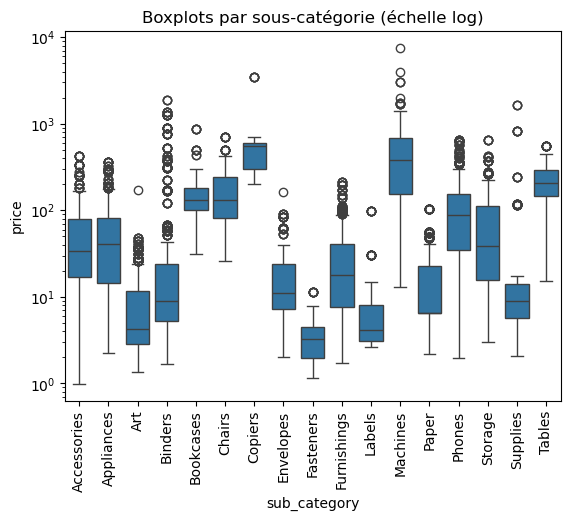

In [41]:
sns.boxplot(
    data=df_clean,
    x="sub_category",
    y="price"
)
plt.title("Boxplots par sous-catégorie (échelle log)")
plt.xticks(rotation=90)
plt.yscale("log")
plt.savefig("test")

Observations : 
---
- Le nombre d'outliers est différent dans chaque sous-catégorie.
- La proportion de ces outliers dans l'ensemble des prix de chaque sous-catégorie varie également selon cette dernière.
- Le nombre total d'observations considérées comme outliers est systématiquement supérieur au nombre de prix extrêmes uniques, indiquant une répétition de ces prix dans les données.
- Les distributions de prix telles que présentées dans le graphique sont asymétriques, avec des valeurs extrêmes qui ne sont en général pas éloignées des autres.
- Certaines sous-catégories méritent cependant un examen plus minutieux :
  - Supplies : presque une deuxième distribution pour les outliers
  - Copiers : 1 seule valeur extrême élevée
  - Art : 1 valeur éloignée des autres
  - Labels : 1 valeur éloignée des autres

## 6.1 Supplies

In [42]:
# Nom des produits et nombre d'apparitions
df_clean[(df_clean["sub_category"] == "Supplies") & (df_clean["price"] > 110)].value_counts("product_name")

product_name
Compact Automatic Electric Letter Opener              8
Premier Electric Letter Opener                        8
Martin Yale Chadless Opener Electric Letter Opener    6
Premier Automatic Letter Opener                       5
High Speed Automatic Electric Letter Opener           3
Name: count, dtype: int64

In [43]:
(
    df_clean[
    (df_clean["sub_category"] == "Supplies") 
    & (df_clean["price"] > 110)
        ]
    [["product_name", "price", "quantity", "unit_cost"]]
    .sort_values("product_name")
)

,product_name,price,quantity,unit_cost
9763,Compact Automatic Electric Letter Opener,119.31,2,116.92
5448,Compact Automatic Electric Letter Opener,119.31,3,116.92
3990,Compact Automatic Electric Letter Opener,119.31,3,116.92
3943,Compact Automatic Electric Letter Opener,119.31,7,116.92
5708,Compact Automatic Electric Letter Opener,119.31,3,116.92
2739,Compact Automatic Electric Letter Opener,119.31,4,116.92
5820,Compact Automatic Electric Letter Opener,119.31,2,116.92
7086,Compact Automatic Electric Letter Opener,119.31,2,116.92
5884,High Speed Automatic Electric Letter Opener,1637.53,3,1572.03
5198,High Speed Automatic Electric Letter Opener,1637.53,3,1572.03


Observations : 
---
- Les produits sont tous des ouvre-lettres électriques
- Chaque produit apparaît au moins 3 fois.
- Le coût unitaire est cohérent avec le prix.
- Les quantités vendues sont également cohérentes.

Décision : 
---
Conservation de toutes les valeurs.

## 6.2 Copiers

In [44]:
# Nom des produits et nombre d'apparitions
df_clean[(df_clean["sub_category"] == "Copiers") & (df_clean["price"] > 3000)].value_counts("product_name")

product_name
Canon imageCLASS 2200 Advanced Copier    5
Name: count, dtype: int64

In [45]:
(
    df_clean[
    (df_clean["sub_category"] == "Copiers") 
    & (df_clean["price"] > 3000)
        ]
    [["product_name", "price", "quantity", "unit_cost", "segment"]]
)

,product_name,price,quantity,unit_cost,segment
2623,Canon imageCLASS 2200 Advanced Copier,3499.99,4,1819.99,Home Office
4190,Canon imageCLASS 2200 Advanced Copier,3499.99,3,1819.99,Consumer
6425,Canon imageCLASS 2200 Advanced Copier,3499.99,4,1819.99,Consumer
6826,Canon imageCLASS 2200 Advanced Copier,3499.99,5,1819.99,Corporate
8153,Canon imageCLASS 2200 Advanced Copier,3499.99,4,1819.99,Consumer


In [46]:
(
    df_clean[
    (df_clean["sub_category"] ==  "Copiers")
    & (df_clean["product_name"].str.contains("Canon")) 
        ]
    [["product_name", "price", "quantity", "unit_cost"]]
    .sort_values("product_name")
)

,product_name,price,quantity,unit_cost
515,Canon Image Class D660 Copier,599.99,5,323.99
8820,Canon Image Class D660 Copier,599.99,2,323.99
3273,Canon Imageclass D680 Copier / Fax,699.99,6,384.99
1233,Canon Imageclass D680 Copier / Fax,699.99,2,384.99
1549,Canon Imageclass D680 Copier / Fax,699.99,1,384.99
3055,Canon Imageclass D680 Copier / Fax,699.99,5,384.99
7520,Canon Imageclass D680 Copier / Fax,699.99,2,384.99
6649,Canon PC-428 Personal Copier,199.99,2,105.99
9839,Canon PC-428 Personal Copier,199.99,3,105.99
4639,Canon PC-428 Personal Copier,199.99,8,105.99


Observations : 
---
- 5 ventes de ce photocopieur de marque Canon ont été enregistrées.
- La quantité vendue lors de chaque commande ne sort pas du lot comparé au produit de la même marque.
- Le prix est presque 2 fois supérieur au coût unitaire mais cela est également le cas d'autres produits de la même sous-catégorie.
- Le prix est 5 fois supérieur à celui du deuxième photocopieur le plus cher, également de la marque Canon.

Décision : 
---
A ce stade conservation du produit dans la base mais demande d'informations supplémentaires.

## 6.3 Art

In [47]:
# Nom des produits et nombre d'apparitions
df_clean[(df_clean["sub_category"] == "Art") & (df_clean["price"] > 170)].value_counts("product_name")

product_name
Hunt BOSTON Model 1606 High-Volume Electric Pencil Sharpener, Beige    1
Name: count, dtype: int64

In [48]:
(
    df_clean[
    (df_clean["product_name"] == "Hunt BOSTON Model 1606 High-Volume Electric Pencil Sharpener, Beige") 
        ]
    [["product_name", "price", "quantity", "unit_cost", "order_id"]]
)

,product_name,price,quantity,unit_cost,order_id
67,Hunt BOSTON Model 1606 High-Volume Electric Pe...,173.91,8,125.22,CA-2014-106376


In [49]:
(
    df_clean[
    df_clean["product_name"].str.contains("Electric Pencil Sharpener|Boston|BOSTON|Hunt|HUNT") 
        ]
    [["product_name", "price", "unit_cost"]]
    .drop_duplicates()
    .sort_values("price", ascending = False)
)

,product_name,price,unit_cost
67,Hunt BOSTON Model 1606 High-Volume Electric Pe...,173.91,125.22
307,Boston Heavy-Duty Trimline Electric Pencil Sha...,48.20,34.22
449,Boston 1645 Deluxe Heavier-Duty Electric Penci...,43.98,32.11
1239,Sanford 52201 APSCO Electric Pencil Sharpener,40.97,30.32
111,"Hunt PowerHouse Electric Pencil Sharpener, Blue",37.98,26.59
1407,Panasonic KP-150 Electric Pencil Sharpener,37.74,27.93
1277,Panasonic KP-380BK Classic Electric Pencil Sha...,35.98,26.98
5599,Hunt Boston Vacuum Mount KS Pencil Sharpener,34.99,25.89
2161,Panasonic KP-350BK Electric Pencil Sharpener w...,34.58,24.55
316,"Boston School Pro Electric Pencil Sharpener, 1670",30.98,22.62


In [50]:
(
    df_clean[
    (df_clean["order_id"] == "CA-2014-106376") 
        ]
    [["product_name", "price", "quantity", "unit_cost", "order_id"]]
)

,product_name,price,quantity,unit_cost,order_id
67,Hunt BOSTON Model 1606 High-Volume Electric Pe...,173.91,8,125.22,CA-2014-106376
68,netTALK DUO VoIP Telephone Service,52.49,4,26.24,CA-2014-106376


Observations : 
---
- Le produit est un taille crayon électrique d'une marque ancienne.
- Son prix et son coût unitaire sont quasiment 4 fois plus élevés que ceux du taille crayon électrique de même marque le plus cher et coûteux.
- Le produit n'a été commandé qu'une seule fois lors d'un achat avec un autre bien. 

Décision : 
---
Conservation de l'entrée

## 6.4 Labels

In [51]:
# Nom des produits et nombre d'apparitions
df_clean[(df_clean["sub_category"] == "Labels") & (df_clean["price"] > 98)].value_counts("product_name")

product_name
Dot Matrix Printer Tape Reel Labels, White, 5000/Box    8
Name: count, dtype: int64

In [52]:
(
    df_clean[
    (df_clean["product_name"] == "Dot Matrix Printer Tape Reel Labels, White, 5000/Box") 
        ]
    [["product_name", "price", "quantity", "unit_cost", "customer_id"]]
)

,product_name,price,quantity,unit_cost,customer_id
587,"Dot Matrix Printer Tape Reel Labels, White, 50...",98.31,3,50.14,BD-11725
634,"Dot Matrix Printer Tape Reel Labels, White, 50...",98.31,3,50.14,BD-11605
1621,"Dot Matrix Printer Tape Reel Labels, White, 50...",98.31,8,50.14,JC-15385
1673,"Dot Matrix Printer Tape Reel Labels, White, 50...",98.31,2,50.14,SW-20455
6309,"Dot Matrix Printer Tape Reel Labels, White, 50...",98.31,8,50.14,TP-21565
6315,"Dot Matrix Printer Tape Reel Labels, White, 50...",98.31,2,50.14,NG-18355
6922,"Dot Matrix Printer Tape Reel Labels, White, 50...",98.31,5,50.14,MS-17710
9696,"Dot Matrix Printer Tape Reel Labels, White, 50...",98.31,5,50.14,HK-14890


Observations : 
--- 
- Le produit est un paquet contenant 5000 étiquettes pour imprimante matricielle.
- Il a été commandé à de multiples reprises, dans des quantités différentes par des clients différents.

Décision : 
---
Conservation du produit

---
# 7. Nouvelles variables
---

On crée trois nouvelles variables : les marges bénéficiaires par unité avant et après remise, et l'identifiant localisation

In [53]:
# Colonne Marge unitaire avant réduction
df_clean["upm_pre_discount"] = (df_clean["price"] - df_clean["unit_cost"])/df_clean["price"]

# Colonne Marge après réduction
df_clean["upm_post_discount"] = (df_clean["price"]*(1-df_clean["discount"]) - df_clean["unit_cost"])/df_clean["price"]

# Colonne identifiant localisation 
# On sait que le code postal est unique sauf pour deux villes 
df_clean["location_id"] = df_clean["city"].str[:2].str.upper() + "-" + df_clean["postal_code"].str[:5] 

---
# 8. Contrôles finaux
---

In [54]:
print(f"Nombre de lignes supprimées : {len(df) - len(df_clean)}")

Nombre de lignes supprimées : 1


In [55]:
print(f"Nombre de nouveaux identifiants produits : {df_clean["product_id"].nunique()- df["Product ID"].nunique()}")

Nombre de nouveaux identifiants produits : 32


In [56]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9993 entries, 0 to 9993
Data columns (total 24 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   order_id           9993 non-null   string        
 1   order_date         9993 non-null   datetime64[ns]
 2   ship_date          9993 non-null   datetime64[ns]
 3   ship_mode          9993 non-null   category      
 4   customer_id        9993 non-null   string        
 5   customer_name      9993 non-null   string        
 6   segment            9993 non-null   category      
 7   city               9993 non-null   category      
 8   state              9993 non-null   category      
 9   postal_code        9993 non-null   string        
 10  region             9993 non-null   category      
 11  product_id         9993 non-null   string        
 12  category           9993 non-null   category      
 13  sub_category       9993 non-null   category      
 14  product_name 

Toutes les variables ont été converties vers le type approprié.

In [57]:
# Nombre de lignes
nb_lignes_avant = len(df)
nb_lignes_apres = len(df_clean)

# Nombre de variables
nb_var_avant = len(df.columns)
nb_var_apres = len(df_clean.columns)

# Nombre identifiants produits
nb_product_id_avant = df["Product ID"].nunique()
nb_product_id_apres = df_clean["product_id"].nunique()

# Nombre doublons 
nb_db_avant = df.duplicated().sum()
nb_db_apres = df_clean.duplicated().sum()

noms_lignes = ["Nombre de lignes", "Variables", "Identifiants produits", "Doublons détectés"]
val_avant = [nb_lignes_avant, nb_var_avant, nb_product_id_avant, nb_db_avant]
val_apres = [nb_lignes_apres, nb_var_apres, nb_product_id_apres, nb_db_apres]

print("Résumé du traitement des données")
pd.DataFrame({"Avant" : val_avant,
              "Après" : val_apres}, 
            index = noms_lignes)

Résumé du traitement des données


,Avant,Après
Nombre de lignes,9994,9993
Variables,20,24
Identifiants produits,1862,1894
Doublons détectés,1,0


Conclusion du nettoyage : 
---
Le contrôle qualité n'a pas mis en évidence d'anomalies majeures susceptibles de compromettre les analyses futures. Les principales opérations réalisées ont consisté à harmoniser les types de données, supprimer les doublons, créer des variables dérivées et vérifier la cohérence des identifiants produits et clients. Les valeurs extrêmes observées apparaissent cohérentes avec les caractéristiques des différentes catégories de produits et ont donc été conservées.

---
# 9. Modèle relationnel
---

## 9.1 Table de fait

In [58]:
df_facts = df_clean[["order_id", "order_date", "ship_date", "ship_mode", "customer_id", "location_id", "product_id", "total_sales", "quantity", 
                     "discount", "profit", "upm_pre_discount", "upm_post_discount"]]

## 9.2 Tables de dimension

In [59]:
df_dim_customer = (
    df_clean[["customer_id", "customer_name", "segment"]]
        .drop_duplicates()
        .reset_index(drop = True)
)

df_dim_product = (
    df_clean[["product_id", "category", "sub_category", "product_name", "price", "unit_cost"]]
        .drop_duplicates()
        .reset_index(drop = True)
)

df_dim_location = (
    df_clean[["location_id", "city", "state", "postal_code", "region"]]
        .drop_duplicates()
        .reset_index(drop = True)
)

---
# 10. Export des bases
---

## 10.1 Export vers MySQL 

In [60]:
list_df = ["df_dim_customer", "df_dim_location", "df_dim_product", "df_facts"]

if __name__ == "__main__":
    server_engine = get_engine()
    create_database(server_engine)
    db_engine = get_engine(db_name)
    create_tables(db_engine)
    import_data(list_df, db_engine)
    verify_import(db_engine)

    print("Base créée avec succès.")

Base créée.
9993 lignes importées.
Base créée avec succès.


## 10.2 Export en csv (optionnel)

In [61]:
if export_csv == "oui" : 
    df_facts.to_csv("df_facts.csv", index = False)
    df_dim_customer.to_csv("df_dim_customer.csv", index = False)
    df_dim_product.to_csv("df_dim_product.csv", index = False)
    df_dim_location.to_csv("df_dim_location.csv", index = False)